# CONVIVE · Iteration 2 (real data)

Team 102_A (Convive Lab) · Mobile Data Challenge 2026 · WBS 3.1.7, switch from synthetic to real data.

This notebook runs the whole Iteration 2 pipeline on the real Smart Steps data, from the monthly CSVs to the aggregated tables the dashboard reads.

**Rules.** The data are under NDA. Outputs show only counts, ranges, category names and aggregated tables. Trips and unique visitors are never combined, unique visitors are never summed across days, months or neighbourhoods, and a 0 or NA never means "nobody". The results describe patterns, not causes.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

import analysis as an
import cleaning
import convive as cv
import descriptives as ds
import levels as lv
import loaders as L
import quality as q
import run_iteration2 as run

pd.set_option("display.max_colwidth", 110, "display.width", 180, "display.max_rows", 80)
con = L.connect()
print("Geometry file:", cv.GEO_FILE.relative_to(cv.HERE))

Geometry file: data\geo\barris_bcn.geojson


## 1. Parquet build (3.1.1)

16 GB of CSV do not fit in pandas. Each monthly CSV is converted once to Parquet with DuckDB. The step is idempotent: already converted files are skipped.

In [2]:
manifest = L.build_parquet(verbose=False)
found = [e for e in manifest.values() if e.get("found")]
print(f"{len(found)} files, {sum(e['bytes'] for e in found) / 1024 ** 3:.1f} GB of CSV, {sum(e['rows'] for e in found):,} rows")

384 files, 15.3 GB of CSV, 168,811,386 rows


## 2. Data inventory (3.1.0)

In [3]:
inventory = run.step_inventory(con)
inventory[["dataset", "monthly files found", "missing months", "total size", "total rows", "columns found / expected", "separator", "encoding", "date range"]]

C:\Users\sergi\OneDrive - Universitat Pompeu Fabra\Escritorio\UPF\4t Curs\Project-Management\PROJECT METHODOLOGY AND TEMPLATES\Week 4+ 5\Telefonica-Data-Challenge-CONVIVE\deliverables\iteration2\3.1.0_data_inventory.md


,dataset,monthly files found,missing months,total size,total rows,columns found / expected,separator,encoding,date range
0,M1,32 of 32,none,1.92 GB,"16,560,949",13 / 13,"','",utf-8,2023-01-01 to 2025-08-31
1,M2,32 of 32,none,4.74 GB,"64,880,151",9 / 9,"','",utf-8,2023-01-01 to 2025-08-31
2,M3,32 of 32,none,8.50 GB,"85,823,522",13 / 13,"','",utf-8,2023-01-01 to 2025-08-31
3,T1,32 of 32,none,0.0 MB,160,7 / 7,';',utf-8,202301 to 202508
4,T2,32 of 32,none,0.3 MB,"4,855",8 / 8,';',utf-8,2023-01-01 to 2025-08-31
5,T3,32 of 32,none,0.1 MB,"1,942",9 / 9,';',utf-8,2023-01-02 to 2025-08-31
6,T4,32 of 32,none,0.8 MB,"11,667",8 / 8,';',utf-8,202301 to 202508
7,T5,32 of 32,none,25.7 MB,"350,537",9 / 9,';',utf-8,2023-01-01 to 2025-08-31
8,T6,32 of 32,none,28.8 MB,"385,959",9 / 9,';',utf-8,202301 to 202508
9,T7,32 of 32,none,11.0 MB,"183,178",8 / 8,';',utf-8,202301 to 202508


## 3. Inspection (3.1.1)

Column types, distinct values and shares of NA and zeros. The full version is in `3.1.1_inspection_summary.md`.

In [4]:
inspection = run.step_inspect(con)
pd.DataFrame([{"dataset": k, "rows": f"{v['rows']:,}", "columns": len(v["table"])} for k, v in inspection.items()])

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

C:\Users\sergi\OneDrive - Universitat Pompeu Fabra\Escritorio\UPF\4t Curs\Project-Management\PROJECT METHODOLOGY AND TEMPLATES\Week 4+ 5\Telefonica-Data-Challenge-CONVIVE\deliverables\iteration2\3.1.1_inspection_summary.md


,dataset,rows,columns
0,M1,"16,560,949",13
1,M2,"64,880,151",9
2,M3,"85,823,522",13
3,T1,160,7
4,T2,"4,855",8
5,T3,"1,942",9
6,T4,"11,667",8
7,T5,"350,537",9
8,T6,"385,959",9
9,T7,"183,178",8


In [5]:
inspection["M1"]["table"]

,column,dtype,distinct,null,'NA' text,'-' text,zero,min to max,values (categorical)
0,day,VARCHAR,971,0.00%,0.00%,0.00%,,,
1,day_of_the_week,VARCHAR,7,0.00%,0.00%,0.00%,,,"Domingo, Jueves, Lunes, Martes, Miércoles, Sábado, Viernes"
2,month,VARCHAR,12,0.00%,0.00%,0.00%,,,"01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11, 12"
3,origen,VARCHAR,4,0.00%,0.00%,0.00%,,,"Internacional, Nacional, Regional, Residente"
4,municipio_origen,VARCHAR,1,0.00%,0.00%,0.00%,,,08019
5,municipio_origen_name,VARCHAR,1,0.00%,0.00%,0.00%,,,Barcelona
6,barrio_origen,VARCHAR,73,0.00%,0.00%,0.00%,,,
7,barrio_origen_name,VARCHAR,73,0.00%,0.00%,0.00%,,,
8,municipio_destino,VARCHAR,1,0.00%,0.00%,0.00%,,,08019
9,municipio_destino_name,VARCHAR,1,0.00%,0.00%,0.00%,,,Barcelona


In [6]:
inspection["T4"]["table"]

,column,dtype,distinct,null,'NA' text,'-' text,zero,min to max,values (categorical)
0,año,VARCHAR,3,0.00%,0.00%,0.00%,,,"2023, 2024, 2025"
1,mes,VARCHAR,32,0.00%,0.00%,0.00%,,,
2,cod_municipio,VARCHAR,1,0.00%,0.00%,0.00%,,,08019
3,cod_barrio,VARCHAR,73,0.00%,0.00%,0.00%,,,
4,desc_municipio,VARCHAR,1,0.00%,0.00%,0.00%,,,Barcelona
5,origen,VARCHAR,4,0.00%,0.01%,0.00%,,,"Internacional, NA, Nacional, Regional"
6,tipo_visitante,VARCHAR,3,0.00%,0.01%,0.00%,,,"Excursionista, NA, Turista"
7,visitantes,BIGINT,"10,347",0.00%,,,0.00%,"15 to 958,748",


## 4. Switch from synthetic to real data (3.1.7)

`convive.load(key, mode="real")` now reads the monthly layout through `loaders.py`. `mode="synthetic"` keeps the Iteration 1 behaviour. M2 and M3 need a list of months, because the full period does not fit in pandas.

In [7]:
real_t1, source = cv.load("T1", "real")
print("T1:", source, f"{len(real_t1):,} rows,", real_t1["mes"].nunique(), "months")
real_m1, source = cv.load("M1", "real", months=["2024-07"])
print("M1, one month:", source, f"{len(real_m1):,} rows; columns match the official description:", set(cv.SCHEMAS["M1"]["columns"]) <= set(real_m1.columns))
del real_m1
try:
    cv.load("M3", "real")
except ValueError as error:
    print("M3 without months is refused:", error)

synthetic_t1, source = cv.load("T1", "synthetic")
if synthetic_t1 is None:
    cv.make_synthetic_data()
    synthetic_t1, source = cv.load("T1", "synthetic")
print("Synthetic mode still works:", source, f"{len(synthetic_t1):,} rows")

T1:

 real 160 rows, 32 months


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

M1, one month: real 526,098 rows; columns match the official description: True
M3 without months is refused: M3 is too large for pandas: pass months=[...] or use loaders.load_mobility('M3', lazy=True)


Synthetic mode still works: synthetic 160 rows


## 5. Geographic levels (2.1.1) and temporal levels (2.1.2)

In [8]:
levels_table, geo_report, temporal = run.step_levels(con)
print(f"Iteration 1 code rule matches {geo_report['legacy_matches']} of {geo_report['n_map']} neighbourhoods")
print(f"Correspondence by name matches {geo_report['name_matches']} of {geo_report['n_map']}")
geo_report["coverage"]

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

C:\Users\sergi\OneDrive - Universitat Pompeu Fabra\Escritorio\UPF\4t Curs\Project-Management\PROJECT METHODOLOGY AND TEMPLATES\Week 4+ 5\Telefonica-Data-Challenge-CONVIVE\deliverables\iteration2\2.1.1_geographic_levels.md


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

C:\Users\sergi\OneDrive - Universitat Pompeu Fabra\Escritorio\UPF\4t Curs\Project-Management\PROJECT METHODOLOGY AND TEMPLATES\Week 4+ 5\Telefonica-Data-Challenge-CONVIVE\deliverables\iteration2\2.1.2_temporal_levels.md
Iteration 1 code rule matches 6 of 73 neighbourhoods
Correspondence by name matches 73 of 73


,source,distinct codes,match the map,"in data, not on map","on map, not in data",placeholders,matches with Iteration 1 rule
0,M1 origin,73,73,none,none,none,6
1,M1 destination,73,73,none,none,none,6
2,M3 origin,73,73,none,none,-,6
3,M3 destination,73,73,none,none,-,6
4,T4,73,73,none,none,none,6
5,T5,73,73,none,none,NA,6
6,T6,73,73,none,none,none,6
7,T7,73,73,none,none,NA,6
8,T8,73,73,none,none,none,6
9,T9,73,73,none,none,NA,6


In [9]:
print("Missing days:", [str(d) for d in temporal["missing"]])
print("Incomplete months:", temporal["incomplete"])
temporal["periods"]

Missing days: ['2024-02-11', '2025-04-13', '2025-05-20']
Incomplete months: {'202402': 1, '202504': 1, '202505': 1}


,year,calendar days Jan-Aug,days with data
0,2023,243,243
1,2024,244,243
2,2025,243,241


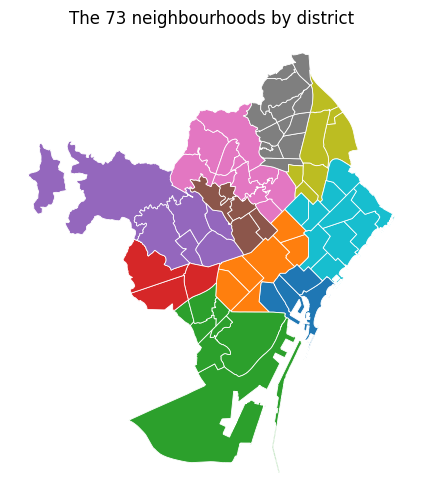

In [10]:
geo, barris = cv.load_barris()
fig, ax = plt.subplots(figsize=(6, 6))
cv.plot_map(geo, ax=ax, title="The 73 neighbourhoods by district")
plt.show()

## 6. Data quality on the real data (3.1.2)

Checks S1 to S4, C1 to C4 and X1 to X3 of `data_review_plan.md`, in SQL so that they also run on M2 and M3. The R1 trigger is evaluated per dataset. The full report is `3.1.2_data_quality_report.md`.

In [11]:
quality_results = run.step_quality(con)
q.r1_assessment(quality_results)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

... (188 outputs left out)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

C:\Users\sergi\OneDrive - Universitat Pompeu Fabra\Escritorio\UPF\4t Curs\Project-Management\PROJECT METHODOLOGY AND TEMPLATES\Week 4+ 5\Telefonica-Data-Challenge-CONVIVE\deliverables\iteration2\3.1.2_data_quality_report.md


,dataset,checks,to review,R1 triggered,reason
0,M1,16,2,yes,censored zeros 42.5%; Iteration 1 code rule matches 6 of 73; fixed by the correspondence
1,M2,14,2,yes,censored zeros 73.4%
2,M3,16,3,yes,repeated keys 43.7%; censored zeros 77.7%; Iteration 1 code rule matches 6 of 73; fixed by the correspondence
3,T1,12,0,no,-
4,T2,14,1,no,-
5,T3,12,2,no,-
6,T4,13,0,yes,Iteration 1 code rule matches 6 of 73; fixed by the correspondence
7,T5,15,1,yes,Iteration 1 code rule matches 6 of 73; fixed by the correspondence
8,T6,10,0,yes,Iteration 1 code rule matches 6 of 73; fixed by the correspondence
9,T7,10,0,yes,Iteration 1 code rule matches 6 of 73; fixed by the correspondence


In [12]:
quality_results["tables"]["M1"]

,check,result,rows affected,status,proposed action
0,S1 Columns match the official description,missing: none; extra: none; renamed in file: ['day_of_the_week'],0,OK,Names mapped in `loaders.COLUMN_RENAMES`
1,S2 Values of `origen`,"Internacional, Nacional, Regional, Residente",0,OK,None
2,S3 Months covered,32 of 32; missing: none,0,OK,None
3,S3 Days covered,"971 of 974 days; missing: 2024-02-11, 2025-04-13, 2025-05-20",0,REVIEW,Flag the affected months (`incomplete_month`); no imputation
4,S3 Dates inside the month of their folder,0 outside,0,OK,None
5,S4 `barrio_origen` codes found on the 73-neighbourhood map,73 of 73 after correspondence (Iteration 1 rule: 6); unknown: none; placeholders: none,0,OK,Apply the correspondence of 2.1.1
6,S4 `barrio_destino` codes found on the 73-neighbourhood map,73 of 73 after correspondence (Iteration 1 rule: 6); unknown: none; placeholders: none,0,OK,Apply the correspondence of 2.1.1
7,C1 Duplicated rows,0 exact duplicates; 0 repeated keys,0,OK,None
8,C2 Empty values (null),none,0,OK,Keep; never read as 0
9,C2 Grouped `NA` segments,0 rows (0.00%),0,OK,Keep as NA; flag (`is_grouped_na`); never read as 0 visitors


In [13]:
quality_results["tables"]["M3"]

,check,result,rows affected,status,proposed action
0,S1 Columns match the official description,missing: none; extra: none; renamed in file: ['day_of_the_week'],0,OK,Names mapped in `loaders.COLUMN_RENAMES`
1,S2 Values of `origen`,"Internacional, Nacional, Regional, Residente",0,OK,None
2,S3 Months covered,32 of 32; missing: none,0,OK,None
3,S3 Days covered,"971 of 974 days; missing: 2024-02-11, 2025-04-13, 2025-05-20",0,REVIEW,Flag the affected months (`incomplete_month`); no imputation
4,S3 Dates inside the month of their folder,0 outside,0,OK,None
5,S4 `barrio_origen` codes found on the 73-neighbourhood map,73 of 73 after correspondence (Iteration 1 rule: 6); unknown: none; placeholders: {'-': 42806807},"42,806,807",OK,Apply the correspondence of 2.1.1
6,S4 `barrio_destino` codes found on the 73-neighbourhood map,73 of 73 after correspondence (Iteration 1 rule: 6); unknown: none; placeholders: {'-': 43016715},"43,016,715",OK,Apply the correspondence of 2.1.1
7,C1 Duplicated rows,"23,790,018 exact duplicates (27.7%); 37,480,772 rows beyond the first per key (43.7%); 14,717,919 keys rep...","37,480,772",REVIEW,"Rows with the same key carry different values, so they are not simple copies: the file seems to have a dim..."
8,C2 Empty values (null),none,0,OK,Keep; never read as 0
9,C2 Grouped `NA` segments,0 rows (0.00%),0,OK,Keep as NA; flag (`is_grouped_na`); never read as 0 visitors


In [14]:
quality_results["tables"]["T4"]

,check,result,rows affected,status,proposed action
0,S1 Columns match the official description,missing: none; extra: none; renamed in file: none,0,OK,None
1,S2 Values of `origen`,"Internacional, NA, Nacional, Regional",1,OK,Keep `NA` as a grouped segment
2,S2 Values of `tipo_visitante`,"Excursionista, NA, Turista",1,OK,Keep `NA` as a grouped segment
3,S2 Regional visitors are always excursionists,0 regional tourist rows,0,OK,None
4,S2 Residents absent from tourism files,0 rows,0,OK,None
5,S3 Months covered,32 of 32; missing: none,0,OK,None
6,S3 `mes` equals the month of the folder,0 differ,0,OK,None
7,S4 `cod_barrio` codes found on the 73-neighbourhood map,73 of 73 after correspondence (Iteration 1 rule: 6); unknown: none; placeholders: none,0,OK,Apply the correspondence of 2.1.1
8,C1 Duplicated rows,0 exact duplicates; 0 repeated keys,0,OK,None
9,C2 Empty values (null),none,0,OK,Keep; never read as 0


In [15]:
cross, details = quality_results["cross"]
cross

,id,check,result,ok
0,X1,Neighbourhood: max daily unique ≤ monthly unique (T5 vs T4),"29 violations in 11,622 cells",REVIEW
1,X2,Month: largest neighbourhood ≤ whole city (T4 vs T1),0 violations in 160 cells,OK
2,X3,Day: sum of neighbourhoods / city (T5 vs T2) = average neighbourhoods visited,median 1.99 (range 1.10 to 2.91),OK


Cross-check with the Iteration 1 function: `convive.review()` runs unchanged on the tourism files, which fit in pandas, and on one month of M1.

In [16]:
for key in ["T1", "T4"]:
    frame, _ = cv.load(key, "real")
    print(key)
    display(cv.review_table(cv.review(frame, key, barris)))
frame, _ = cv.load("M1", "real", months=["2024-07"])
print("M1, July 2024")
display(cv.review_table(cv.review(frame, "M1", barris)))
del frame

T1


,check,result,ok
0,Columns match the official description,"missing=-, extra=-",OK
1,Rows,160,OK
2,Duplicated rows,0,OK
3,Empty values in other columns,none,OK
4,"Share of visitantes = 0 (privacy threshold, NOT 'no mobility')",0.0%,OK
5,Negative visitantes,0,OK
6,Values of 'origen',"Internacional, Nacional, Regional",OK
7,Values of 'tipo_visitante',"Excursionista, Turista",OK
8,Period covered,202301 to 202508 (32 of 32 months),OK


T4

,check,result,ok
0,Columns match the official description,"missing=-, extra=-",OK
1,Rows,"11,667",OK
2,Duplicated rows,0,OK
3,Empty values in other columns,none,OK
4,"Grouped 'NA' values (segments < 15 people, kept as NA)","origen: 1, tipo_visitante: 1",OK
5,"Share of visitantes = 0 (privacy threshold, NOT 'no mobility')",0.0%,OK
6,Negative visitantes,0,OK
7,Values of 'origen',"Internacional, NA, Nacional, Regional",OK
8,Values of 'tipo_visitante',"Excursionista, NA, Turista",OK
9,Period covered,202301 to 202508 (32 of 32 months),OK


M1, July 2024


,check,result,ok
0,Columns match the official description,"missing=-, extra=-",OK
1,Rows,"526,098",OK
2,Duplicated rows,0,OK
3,Empty values in other columns,none,OK
4,"Share of viajes = 0 (privacy threshold, NOT 'no mobility')",42.3%,OK
5,Negative viajes,0,OK
6,Values of 'origen',"Internacional, Nacional, Regional, Residente",OK
7,Days covered,"2024-07-01 to 2024-07-31, 31 days, missing: none",OK
8,'barrio_origen' codes found on the map,73 of 73 (unknown: -),OK
9,'barrio_destino' codes found on the map,73 of 73 (unknown: -),OK


## 7. Cleaning (3.1.3)

Writes clean Parquet to `data/processed/clean/` (git-ignored). Nothing is imputed, NA stays NA and a published 0 stays 0 with a flag.

In [17]:
totals, cleaning_log = run.step_clean(con)
cleaning_log.head(20)

M1: 16,560,949 rows in, 16,560,949 rows out


M2: 64,880,151 rows in, 64,880,151 rows out


M3: 85,823,522 rows in, 85,823,522 rows out


T1: 160 rows in, 160 rows out


T2: 4,855 rows in, 4,855 rows out


T3: 1,942 rows in, 1,942 rows out


... (6 outputs left out)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

C:\Users\sergi\OneDrive - Universitat Pompeu Fabra\Escritorio\UPF\4t Curs\Project-Management\PROJECT METHODOLOGY AND TEMPLATES\Week 4+ 5\Telefonica-Data-Challenge-CONVIVE\deliverables\iteration2\3.1.3_cleaning_log.md


,dataset,rule,rows affected,reason
0,M1,Drop exact duplicates,0,Checked: none found
1,M2,Drop exact duplicates,0,Checked: none found
2,M3,Exact duplicates NOT dropped; flagged `is_exact_repeat`,"23,790,018","Deviation from the plan. Rows sharing a key usually have different values, so an identical pair can be two..."
3,M3,Rows sharing a key flagged with `key_rows`,"52,198,691",The file seems to have a dimension that is not in the description
4,T1,Drop exact duplicates,0,Checked: none found
5,T2,Drop exact duplicates,0,Checked: none found
6,T3,Drop exact duplicates,0,Checked: none found
7,T4,Drop exact duplicates,0,Checked: none found
8,T5,Drop exact duplicates,0,Checked: none found
9,T6,Drop exact duplicates,0,Checked: none found


## 8. Aggregated statistics (3.1.6)

These tables are the dashboard's only input. Values below 15 are written as `<15`.

In [18]:
tables, headlines = run.step_stats(con)
for path in sorted(ds.STATS_DIR.glob("*.csv")):
    print(f"{path.name:45s} {path.stat().st_size / 1024:8,.0f} KB")

Computing statistics tables


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

  city_monthly_by_origin_type.csv: 160 rows, 9 KB


  city_weekday_by_origin.csv: 105 rows, 6 KB


  city_daily_by_origin.csv: 4,855 rows, 364 KB


  barrio_monthly_by_origin_type.csv: 11,680 rows, 1,133 KB


... (2 outputs left out)

  city_yoy_jan_aug.csv: 11 rows, 1 KB


  barrio_incoming_trips_by_origen.csv: 65,393 rows, 7,457 KB


  overnight_stays_distribution.csv: 42 rows, 2 KB


C:\Users\sergi\OneDrive - Universitat Pompeu Fabra\Escritorio\UPF\4t Curs\Project-Management\PROJECT METHODOLOGY AND TEMPLATES\Week 4+ 5\Telefonica-Data-Challenge-CONVIVE\deliverables\iteration2\3.1.6_summary.md
barrio_concentration.csv                            25 KB
barrio_incoming_trips_by_origen.csv              7,457 KB
barrio_monthly_by_origin_type.csv                1,133 KB
barrio_yoy_jan_aug.csv                              91 KB
city_daily_by_origin.csv                           364 KB
city_monthly_by_origin_type.csv                      9 KB
city_weekday_by_origin.csv                           6 KB
city_yoy_jan_aug.csv                                 1 KB
overnight_stays_distribution.csv                     2 KB


In [19]:
paragraphs = ds.question_paragraphs(headlines)
for qid, p in paragraphs.items():
    print(f"{qid}. {p['title']}\n   {p['text']}\n   Limitation: {p['limit']}\n")

Q1. How concentrated are visitors across the 73 neighbourhoods?
   In the median month, the 10 highest neighbourhoods hold 50.2% of the neighbourhood ranking (range 46.2% to 55.2% over 32 months). 10 of 73 is 13.7% of the neighbourhoods. The median Gini across neighbourhoods is 0.590. The highest monthly averages are la Dreta de l'Eixample (1,843,274), el Barri Gòtic (1,267,529), la Sagrada Família (889,225); the lowest is Verdun (986, an unusually low value flagged in 3.1.2). Median top-10 share by origin: Internacional 62.1%, Nacional 47.6%, Regional 38.0%.
   Limitation: Neighbourhood values are not additive: a person visiting two neighbourhoods counts in both, so this is a share of the ranking, not of the city total.

Q2. How much do visitors change from month to month, by origin?
   Peak-to-trough ratio of monthly unique visitors: 1.44 in 2023 (peak July 2023, low February 2023) and 1.40 in 2024 (peak July 2024, low January 2024). June to August average is 1.13 and 1.14 times the 

## 9. First look at the aggregated tables

The dashboard shows these with filters. Colours per origin are the same in both.

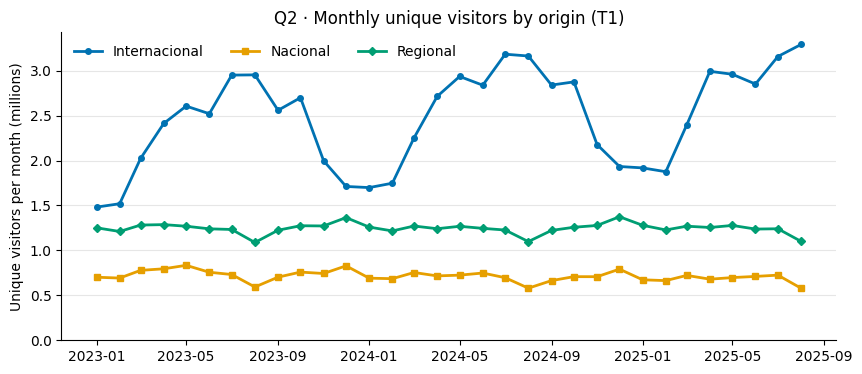

In [20]:
COLORS = {"Internacional": "#0072B2", "Nacional": "#E69F00", "Regional": "#009E73"}
MARKERS = {"Internacional": "o", "Nacional": "s", "Regional": "D"}
city = pd.read_csv(ds.STATS_DIR / "city_monthly_by_origin_type.csv", dtype={"mes": str})
city["visitantes"] = pd.to_numeric(city["visitantes"], errors="coerce")
series = city.groupby(["mes", "origen"])["visitantes"].sum().unstack()
series.index = pd.to_datetime(series.index, format="%Y%m")
fig, ax = plt.subplots(figsize=(10, 4))
for origin in series.columns:
    ax.plot(series.index, series[origin] / 1e6, color=COLORS[origin], marker=MARKERS[origin], markersize=4, lw=2, label=origin)
ax.set_ylabel("Unique visitors per month (millions)")
ax.set_title("Q2 · Monthly unique visitors by origin (T1)")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e6e6e6")
ax.set_ylim(bottom=0)
ax.legend(frameon=False, ncol=3)
plt.show()

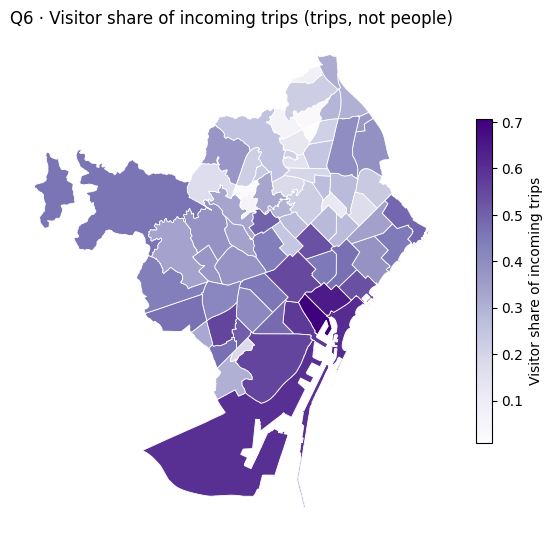

In [21]:
trips = pd.read_csv(ds.STATS_DIR / "barrio_incoming_trips_by_origen.csv", dtype={"cod_barrio": str, "mes": str})
trips["viajes"] = pd.to_numeric(trips["viajes"], errors="coerce").fillna(0)
total = trips.groupby("cod_barrio")["viajes"].sum()
share = trips[trips["origen"] != "Residente"].groupby("cod_barrio")["viajes"].sum() / total
values = dict(zip(barris["cod_barrio"], barris["cod_barrio_ss"].map(share)))
fig, ax = plt.subplots(figsize=(7, 7))
cv.plot_map(geo, values=values, ax=ax, cmap="Purples", legend_label="Visitor share of incoming trips",
            title="Q6 · Visitor share of incoming trips (trips, not people)")
plt.show()

## 10. Standalone maps (4.2.1) and deliverables

In [22]:
run.step_maps(con)
con.close()
for path in sorted(q.DELIVERABLES.iterdir()):
    print(path.name)

Maps written


2.1.1_geographic_levels.csv
2.1.1_geographic_levels.md
2.1.2_temporal_levels.md
3.1.0_data_inventory.md
3.1.1_inspection_summary.md
3.1.2_data_quality_report.md
3.1.3_cleaning_log.md
3.1.6_stats
3.1.6_summary.json
3.1.6_summary.md
3.2.0_ResearchQuestions.md
4.1.1_dashboard_layout.md
4.1.1_dashboard_layout.png
4.1.3_VisualisationEnvironment.md
4.2.0_dashboard_notes.md
4.2.1_map_visitor_share_trips.html
4.2.1_map_visitors.html
CONVIVE_Iteration2_Delivery.docx
screenshots


## 11. Limits

- Trips are not visitors, and the two are never mixed.
- Published zeros in mobility mean fewer than 15 trips, so totals of trips are lower estimates.
- M3 has repeated keys with different values. It is not used here, and the question goes to the mentor before Iteration 3.
- The dashboard is started with `streamlit run app/dashboard.py`.